# ARN circulaire : repliement en paires sans croisement

**Navigation** : [↑ Bio & Médecine — sommaire de la série](../README.md) · [Structures — sommaire du pli](README.md) · feuille précédente : [Structures-02 — repliement sur réseau, énergie et isopérimétrie](Structures-02-Repliement-Reseau-Energie-Isoperimetrie-Python.ipynb)

Ce carnet est la troisième feuille du pli **Structures** de la série **Bio & Médecine**. Structures-02 cherchait le minimum d'une énergie sur un réseau carré ; ici l'objet change de nature : la molécule est un **ARN circulaire**, et l'on ne minimise plus rien. Une structure secondaire d'ARN est un ensemble de paires entre nucléotides — A avec U, G avec C — qui ne se croisent pas. Les **viroïdes**, les plus petits réplicons connus, sont exactement de tels ARN : circulaires, longs de 250 à 400 nucléotides, sans protéine, et classés par leur structure secondaire. Le carnet compte les paires qu'une telle molécule peut porter, en ligne et sur un cercle, et contrôle chaque compte par une voie indépendante.

**Objectifs d'apprentissage.** À la fin du carnet, vous savez énoncer le modèle des paires sans croisement et la condition de boucle minimale ; écrire et justifier la récurrence qui maximise le nombre de paires d'une chaîne linéaire ; démontrer qu'un repliement circulaire est un repliement linéaire restreint, et en tirer les trois conséquences ; construire deux contrôles indépendants, par énumération exhaustive et par programme linéaire en nombres entiers, et reconnaître ce qu'une formulation oublieuse de contrainte rend de faux ; mesurer l'écart entre une borne de composition et l'optimum, et l'effet de la longueur de boucle, de la composition et de la longueur.

**Prérequis.** Python, `numpy`, et la programmation dynamique sur des intervalles. Structures-02 n'est pas un prérequis technique : le carnet se lit seul ; il en reprend le contrat de méthode et le goût du contrôle indépendant.

**Durée estimée.** Une minute et demie d'exécution, une heure de lecture ; les trois exercices demandent environ une heure de plus.

Le carnet applique à cette question le contrat de méthode de la série :

1. **Modèle** — il énonce une séquence sur quatre lettres, deux règles d'appariement, l'interdiction de croisement, une boucle minimale déclarée et un objectif : le nombre de paires.
2. **Calcul** — il écrit la récurrence de la chaîne linéaire, démontre le théorème qui ramène le cercle au cas linéaire restreint, et calcule l'optimum par deux écritures du même noyau.
3. **Contrôle indépendant** — il compare chaque optimum à une voie qui ne partage ni récurrence ni formulation : l'énumération exhaustive de toutes les structures, puis un programme linéaire en nombres entiers.
4. **Contre-témoin** — il construit les cas où la lecture intuitive manque : une molécule dont toutes les paires autorisées sont des diamètres et qui n'en garde qu'une, un programme privé de sa contrainte de degré qui apparie une base deux fois, une borne de composition que la molécule n'atteint jamais.
5. **Statut** — il sépare ce qui est mesuré ici, ce qui est cité de l'éditorial sur les viroïdes, et ce qui reste ouvert.

Aucune séquence réelle n'est lue, aucune énergie n'est calculée, aucun paramètre n'est ajusté : tout ce qui suit se déduit du modèle déclaré et de calculs exacts sur de petites molécules.


## Ce que cette feuille établit, et ce qu'elle n'établit pas

| Section | Question | Contrôle indépendant | Contre-témoin |
|---|---|---|---|
| 1 | Quelles paires une molécule courte autorise-t-elle, en ligne et sur le cercle ? | Le même prédicat écrit deux fois, par boucle et par matrice | `AGGGGU` : une paire en ligne, aucune sur le cercle |
| 2 | Combien de paires une structure peut-elle porter ? | Noyau lisible contre noyau vectorisé, sur les deux géométries | `AAAAGGGGUUUU` atteint son plafond, `GCGCGC` en reste à une paire |
| 3 | Que change le cercle ? | L'optimum circulaire contre celui de chacune des rotations | `AUAUAUAUAU` : trois paires en ligne, une seule sur le cercle |
| 4 | Les deux noyaux disent-ils la vérité ? | Énumération exhaustive, puis programme linéaire en nombres entiers | Le même programme privé de sa contrainte de degré apparie une base deux fois |
| 5 | À quel point le plafond de composition est-il atteint ? | Écart mesuré molécule par molécule, minimum, moyenne et maximum | L'écart moyen passe de 5.335 à 32.550 quand la longueur croît |
| 6 | Quels paramètres font varier l'optimum ? | Deux balayages indépendants, cinquante molécules par case | L'optimum remonte aux deux extrémités de la composition |
| 7 | L'optimum suffit-il à décrire une molécule ? | Énumération complète des structures optimales de chaque séquence | À neuf bases, aucune des 510 séquences n'a une structure optimale unique |

**Ce que la feuille apporte au pli** : le passage d'une chaîne à une molécule qui se referme. Structures-02 cherchait une conformation d'énergie minimale ; ici la géométrie est fixée — des paires, pas de croisement — et la topologie change tout : sur un cercle, l'optimum d'une molécule n'est l'optimum d'aucune de ses coupes, et le carnet le mesure. L'instrument est le compte de paires, celui que l'algorithme de Nussinov maximise ; la feuille suivante y ajoutera une énergie.

Ce carnet **n'établit pas** quelle structure secondaire adopte un viroïde réel : aucune séquence n'est lue, aucune énergie n'est calculée, et la longueur de boucle est une convention déclarée. Il établit ce qu'un modèle de comptage dit exactement d'un ARN circulaire, et à quelles conditions ce modèle peut servir de juge.


## Outils et conventions

Le carnet n'utilise que des bibliothèques de calcul scientifique : `numpy` pour les tableaux, `scipy.optimize.milp` pour le programme linéaire en nombres entiers, `scipy.sparse` pour en assembler les contraintes, `matplotlib` pour les figures. Il ne lit aucun fichier et n'appelle aucun service.

**Le modèle déclaré.** Une molécule est une suite de nucléotides pris dans $\{A, U, G, C\}$. Une **paire** unit deux positions $i < j$ dont les lettres sont complémentaires : A avec U, G avec C. Une **structure** est un ensemble de paires tel qu'aucune position ne serve deux fois et qu'aucune paire n'en croise une autre — deux paires $(i, j)$ et $(k, l)$ se croisent quand $i < k < j < l$ ou $k < i < l < j$.

**La boucle minimale.** Les deux positions d'une paire ne peuvent pas être collées : au moins $\ell$ positions doivent les séparer, ce qui s'écrit $j - i > \ell$. Le carnet prend $\ell = 3$ partout, valeur déclarée et non mesurée ; la section 6 en mesure le coût.

**Sur un cercle.** La molécule n'a plus d'extrémités : une structure est un ensemble de cordes, et la condition de boucle vaut des deux côtés de chaque paire. La boucle qui passe par l'origine compte donc aussi, et la paire $(i, j)$ n'est autorisée que si $j - i > \ell$ et $n - (j - i) > \ell$.

**L'objectif.** Une structure vaut son nombre de paires. Aucune énergie, aucun empilement, aucune pénalité de boucle : c'est le modèle que l'algorithme de Nussinov maximise, et c'est le seul que le carnet emploie.

**Paramètres déclarés.** Les longueurs, les graines et les tailles de balayage sont écrites dans le code, en tête des blocs qui les utilisent.

**Tout ce qui est aléatoire est semé.** Une exécution à l'identique rend les mêmes nombres ; les temps d'exécution, eux, dépendent de la machine.

**Citations.** Les passages de l'éditorial sur les viroïdes sont donnés en anglais, dans l'orthographe de la copie archivée. L'algorithme de Nussinov est nommé par son nom d'usage ; l'article de 1980 n'est pas archivé dans le gisement partagé et rien n'en est emprunté.

Le premier bloc charge ces bibliothèques et fixe la taille des figures.


In [1]:
# Bibliotheques utilisees dans tout le carnet, et taille commune des figures
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import coo_matrix, vstack

plt.rcParams.update({
    'figure.figsize': (7.5, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

print(f'numpy {np.__version__} | scipy {scipy.__version__}')


numpy 2.4.6 | scipy 1.18.1


## 1. La molécule, la paire et la boucle

### Ce que dit l'éditorial

L'éditorial de *Virus Research* présente les viroïdes par ce qu'ils sont :

> … minimal non-protein-coding circular RNAs … able to replicate and incite diseases in plants …

La parenthèse de cette phrase donne leur longueur : 250 à 400 nucléotides. Le même texte donne le critère de leur classification :

> Currently, viroids are classified by the International Committee Taxonomy of Viruses into two families based on differences in their replication site and strategy and in their secondary structure: *Avsunviroidae* and *Pospiviroidae*.

Et il rappelle ce que le génome circulaire a de particulier, à propos des viroïdes et des deltavirus humains :

> … both of which have commonality such as the circular nature of genomic RNAs and autocatalytic ribozyme activity …

*Source : Pallas, Di Serio et Suzuki, éditorial du numéro spécial « The simplest RNA replicons, viroids »,* Virus Research *323 (2023) 198996 — <https://doi.org/10.1016/j.virusres.2022.198996>. Copie archivée : `G:\\Mon Drive\\MyIA\\IA\\Bibliographie IA\\Biology\\2023 - Pallas Di Serio Suzuki - The simplest RNA replicons, viroids - A tribute to Ricardo Flores (Virus Research 323, 198996, PMC10194228, CC BY-NC-ND, OA).xml`.*

### Ce que ces passages disent, et ce qu'ils ne disent pas

Trois faits sont posés : la molécule est un ARN circulaire, sa longueur va de 250 à 400 nucléotides, et sa **structure secondaire** est un critère de classification officielle — donc un objet qu'on sait déterminer et comparer. Le génome est circulaire, et la circularité est un trait partagé avec d'autres réplicons.

Rien, en revanche, ne dit comment une structure secondaire se calcule, ni selon quel critère on la choisit. Aucune énergie n'est donnée, aucun algorithme n'est nommé. C'est la place exacte du modèle du carnet : il déclare des paires, une interdiction de croisement et une boucle minimale, et il compte.

### La question posée

Une molécule circulaire peut-elle porter plus de paires que la même molécule coupée en un point quelconque ? La réponse n'est pas évidente : couper retire les paires qui franchissaient la coupure, mais refermer en ajoute d'autres. Le carnet montre que la réponse est **non**, et il la mesure sur des molécules tirées au hasard.

Aucune séquence de viroïde n'est lue dans ce carnet. Les longueurs citées ici servent seulement à choisir les tailles de la section 6 : 250 et 400 nucléotides y figurent comme les bornes de la fourchette, et les molécules sont tirées au hasard à ces longueurs.


In [2]:
PAIRES = {('A', 'U'), ('U', 'A'), ('G', 'C'), ('C', 'G')}
BOUCLE_MIN = 3


def paire_possible(a, b, boite=False):
    # Deux nucleotides s'apparient-ils ? A-U et G-C toujours ; la paire G-U,
    # dite wobble, seulement si l'option boite est ouverte (exercice 1)
    if (a, b) in PAIRES:
        return True
    return boite and {a, b} == {'G', 'U'}


def autorisee(seq, i, j, ell=BOUCLE_MIN, boite=False, circulaire=False):
    # La paire (i, j), i < j, est-elle autorisee ? Deux conditions : des
    # nucleotides compatibles, et au moins ell positions entre i et j. Sur un
    # cercle, la meme condition vaut pour la boucle qui passe par l'origine :
    # j - i > ell et n - (j - i) > ell
    d = j - i
    if d <= ell or (circulaire and len(seq) - d <= ell):
        return False
    return paire_possible(seq[i], seq[j], boite)


def paires_autorisees(seq, **options):
    return [(i, j) for i in range(len(seq)) for j in range(i + 1, len(seq))
            if autorisee(seq, i, j, **options)]


for exemple in ('AGGGGU', 'AUAUAUAU'):
    print(f'{exemple}, lineaire   : paires autorisees {paires_autorisees(exemple)}')
    print(f'{exemple}, circulaire : paires autorisees {paires_autorisees(exemple, circulaire=True)}')


AGGGGU, lineaire   : paires autorisees [(0, 5)]
AGGGGU, circulaire : paires autorisees []
AUAUAUAU, lineaire   : paires autorisees [(0, 5), (0, 7), (1, 6), (2, 7)]
AUAUAUAU, circulaire : paires autorisees []


### Lecture du résultat

Deux molécules de six et huit nucléotides suffisent à voir ce que le cercle change.

Pour `AGGGGU`, une seule paire est autorisée en ligne, la paire $(0, 5)$ : quatre positions les séparent, donc $5 - 0 = 5 > \ell$, et la molécule porte une A en tête et un U en queue. Sur le cercle, la même paire devrait encore laisser plus de trois positions de l'autre côté de l'origine ; la boucle fermée n'en contient aucune de libre, car $6 - 5 = 1$. La paire est donc refusée, et avec elle toute possibilité de structure : l'optimum passe de une à zéro paire.

Pour `AUAUAUAU`, les paires autorisées en ligne sont $(0, 5)$, $(0, 7)$, $(1, 6)$ et $(2, 7)$ : les distances valent 5 ou 7, aucune n'est inférieure ou égale à trois. Sur le cercle, il faudrait en plus $8 - d > \ell$, c'est-à-dire $d < 5$ ; comme les distances valent 5 et 7, aucune ne passe. L'optimum circulaire est nul, tandis que l'optimum linéaire vaut deux paires, par exemple $(0, 7)$ et $(1, 6)$, emboîtées.

Ces deux exemples disent la nature du changement : refermer la molécule ne retire pas quelques paires au bord, il peut retirer **toutes** les paires d'une molécule courte, parce que la condition de boucle s'applique maintenant des deux côtés de chaque corde.


## 2. La récurrence linéaire

Avant de refermer la molécule, on la coupe. Soit $L[i][j]$ le plus grand nombre de paires d'une structure sans croisement de la sous-chaîne $i, i+1, \dots, j$. La récurrence tient en trois cas :

$$L[i][j] = \max\Bigl(L[i][j-1],\ \bigl[(i, j)\ \text{autorisée}\bigr]\bigl(1 + L[i+1][j-1]\bigr),\ \max_{i < k < j}\bigl(L[i][k-1] + L[k][j]\bigr)\Bigr)$$

**Les trois cas couvrent tout, exactement.**

- Si $(i, j)$ est une paire de la structure, aucune autre paire ne peut la franchir : toutes les autres sont à l'intérieur, d'où $1 + L[i+1][j-1]$.
- Sinon, la position $i$ n'est appariée à aucune position avant $j$, ou elle ne l'est pas du tout. Soit $k = i+1$ dans le second cas, et $k = p+1$ si $i$ est appariée à $p < j$ dans le premier. Aucune paire ne traverse alors la frontière entre $k-1$ et $k$ : la structure se partage en deux blocs indépendants, d'où $L[i][k-1] + L[k][j]$.
- Le premier terme, $L[i][j-1]$, couvre la situation où $j$ ne porte aucune paire ; il est en fait contenu dans le troisième cas, avec $k = j$, mais l'écrire séparément rend la lecture immédiate.

Chaque cas produit une structure valide, et toute structure tombe dans l'un des cas : le maximum des trois est donc à la fois un minorant et un majorant de $L[i][j]$, c'est-à-dire $L[i][j]$. Les cases se remplissent par longueur croissante de la sous-chaîne, et le résultat cherché est $L[0][n-1]$. Le coût est cubique en la longueur : $n^2$ cases, et un maximum sur $k$ de longueur $n$ pour chacune.

C'est la récurrence que la littérature associe au nom de Nussinov. Le carnet ne l'emprunte pas : elle se redémontre ci-dessus, et les sections 4 et 5 la contrôlent par deux voies indépendantes. Une structure optimale se relit dans la table en redescendant, ce que fait la fonction de la cellule suivante pour la molécule de démonstration.


In [3]:
def table(seq, ell=BOUCLE_MIN, boite=False, circulaire=False):
    # Noyau lisible. L[i][j] = nombre maximal de paires d'une structure sans
    # croisement de la sous-chaine [i, j]. Les cases se remplissent par
    # longueur croissante de la sous-chaine : tout ce dont une case a besoin
    # est deja calcule
    n = len(seq)
    L = [[0] * n for _ in range(n)]
    for d in range(1, n):
        for i in range(n - d):
            j = i + d
            L[i][j] = L[i][j - 1]
            if autorisee(seq, i, j, ell, boite, circulaire):
                L[i][j] = max(L[i][j], 1 + L[i + 1][j - 1])
            for k in range(i + 1, j):
                L[i][j] = max(L[i][j], L[i][k - 1] + L[k][j])
    return L


def optimum(seq, **options):
    # Le nombre maximal de paires de la sequence entiere
    return table(seq, **options)[0][len(seq) - 1]


def retrace(seq, L=None, **options):
    # Une structure qui realise l'optimum, lue en redescendant dans la table
    L = table(seq, **options) if L is None else L
    paires = []

    def descends(i, j):
        if i >= j:
            return
        if autorisee(seq, i, j, **options) and L[i][j] == 1 + L[i + 1][j - 1]:
            paires.append((i, j))
            descends(i + 1, j - 1)
        elif L[i][j] == L[i][j - 1]:
            descends(i, j - 1)
        elif L[i][j] == L[i + 1][j]:
            descends(i + 1, j)
        else:
            k = next(k for k in range(i + 1, j) if L[i][j] == L[i][k - 1] + L[k][j])
            descends(i, k - 1)
            descends(k, j)

    descends(0, len(seq) - 1)
    return paires


DEMO = 'AUAUAUAU'
print(f'optimum lineaire de {DEMO} : {optimum(DEMO)} paires, par exemple {retrace(DEMO)}')


optimum lineaire de AUAUAUAU : 2 paires, par exemple [(0, 7), (1, 6)]


In [4]:
def borne_composition(seq):
    # Chaque paire consomme un nucleotide de chaque sorte : au plus
    # min(nb A, nb U) paires A-U, et min(nb G, nb C) paires G-C
    return min(seq.count('A'), seq.count('U')) + min(seq.count('G'), seq.count('C'))


TEMOINS = ('AGGGGU', 'GGGGAAUUCC', 'AUAUAUAUAU', 'GCGCGC', 'AAAAGGGGUUUU')
print('sequence         n   lineaire   circulaire   paires possibles')
for s in TEMOINS:
    print(f'{s:15s} {len(s):3d} {optimum(s):10d} {optimum(s, circulaire=True):12d} '
          f'{borne_composition(s):18d}')


sequence         n   lineaire   circulaire   paires possibles
AGGGGU            6          1            0                  1
GGGGAAUUCC       10          2            1                  4
AUAUAUAUAU       10          3            1                  5
GCGCGC            6          1            0                  3
AAAAGGGGUUUU     12          4            2                  4


### Lecture du résultat

Cinq molécules choisies à la main, trop courtes pour que le hasard y joue un rôle, disent ce que le compte mesure.

| Molécule | n | Optimum linéaire | Optimum circulaire | Plafond de composition |
|---|---|---|---|---|
| `AGGGGU` | 6 | 1 | 0 | 1 |
| `GGGGAAUUCC` | 10 | 2 | 1 | 4 |
| `AUAUAUAUAU` | 10 | 3 | 1 | 5 |
| `GCGCGC` | 6 | 1 | 0 | 3 |
| `AAAAGGGGUUUU` | 12 | 4 | 2 | 4 |

`AGGGGU` et `GCGCGC` perdent toute paire en se refermant, et l'on peut le vérifier sur la molécule elle-même. Pour `AGGGGU`, A en tête et U en queue : la seule paire possible est $(0, 5)$, à distance 5, et la boucle de l'autre côté ne contient aucune position libre, car $6 - 5 = 1$. Pour `GCGCGC`, G et C alternent, et la seule paire G–C dont la distance dépasse trois est encore $(0, 5)$ ; toutes les autres sont à distance 1 ou 3. Le plafond, lui, vaut trois — il compte des lettres, pas des distances.

`GGGGAAUUCC` est l'exemple de l'arrangement, et il vaut d'être détaillé. Huit paires G–C sont autorisées, toutes entre un G du début et un C de la fin ; aucune paire A–U ne l'est, car les deux A et les deux U sont voisins au milieu de la molécule. Le plafond vaut quatre — deux paires G–C et deux paires A–U — mais les paires A–U n'existent pas dans cet arrangement, et les quatre G ne peuvent s'apparier qu'aux deux C : la structure linéaire en prend deux, emboîtées, $(0, 9)$ et $(1, 8)$. Sur le cercle il n'en reste qu'une, par exemple $(2, 8)$, parce que les paires qui franchissent l'origine sont refusées.

`AUAUAUAUAU` est le cas le plus net. Neuf paires A–U sont autorisées en ligne, et la structure en prend trois, emboîtées : $(0, 9)$, $(1, 8)$ et $(2, 7)$ — c'est la seule structure optimale. Sur un cercle de dix positions, la condition des deux côtés impose $3 < d < 7$, donc $d = 5$ : **toutes** les paires autorisées ont la même distance, 5, soit un demi-tour. Ce sont des diamètres, ils se coupent tous au centre, et la structure n'en garde qu'un — cinq structures optimales, une par diamètre.

`AAAAGGGGUUUU` atteint son plafond en ligne, quatre paires emboîtées de $(0, 11)$ à $(3, 8)$, et en perd la moitié sur le cercle : deux paires seulement, par exemple $(1, 9)$ et $(2, 8)$, parce que les appariements qui passent par l'origine sont interdits.


## 3. Le cercle

Un repliement circulaire n'est pas un nouveau problème : c'est le même, restreint.

**Théorème.** Soit $S$ l'ensemble des paires autorisées sur le cercle. Une structure circulaire sans croisement est exactement une structure linéaire sans croisement formée de paires de $S$. Par conséquent la récurrence de la section 2, appliquée avec le prédicat circulaire, calcule l'optimum circulaire.

**Démonstration.** Deux cordes d'un cercle se croisent si et seulement si leurs extrémités alternent sur le cercle — $i < k < j < l$ ou $k < i < l < j$. Cette relation ne dépend pas du point où l'on coupe le cercle pour le lire comme une chaîne : couper entre deux positions transforme les cordes en paires, et deux paires alternées restent alternées. Le prédicat circulaire, lui, est le prédicat linéaire augmenté de la condition sur la boucle qui passe par l'origine ; en restreignant $S$ à ces paires, les deux conditions coïncident. La récurrence ne dépend donc que de la relation de croisement et du prédicat : elle calcule le même maximum sur $S$ qu'elle le ferait sur toute paire autorisée. $\square$

**Trois conséquences, toutes mesurées plus loin.**

1. **Invariance par rotation.** Couper la molécule ailleurs ne change pas l'optimum circulaire : la relation d'alternance ne voit pas la coupure. La suite du carnet le vérifie sur chaque rotation de chaque molécule tirée.
2. **Le cercle ne gagne jamais.** À toute coupe, l'optimum circulaire est au plus l'optimum linéaire de la molécule coupée là : les structures circulaires forment un sous-ensemble des structures linéaires de la molécule tournée.
3. **Le cercle n'est pas le maximum des coupes.** L'optimum circulaire est **strictement plus petit** que le meilleur des optimums linéaires sur les rotations, et le carnet en donne un cas mesuré : vingt bases, meilleure coupe à six paires, cercle à quatre.

**Ce que le théorème ne dit pas.** Il ne dit rien des énergies : il porte sur l'ensemble des paires et sur la relation de croisement, pas sur une molécule réelle. Il ne dit pas non plus que le cercle coûte peu — seulement qu'il ne peut pas faire gagner ; les sections 5 et 6 mesurent ce qu'il coûte.

**Deux écritures du même noyau.** La récurrence se prête à une seconde écriture, par diagonales : toutes les sous-chaînes d'une même longueur sont traitées ensemble, et le prédicat devient une matrice booléenne. La cellule qui suit l'écrit ; la suivante la compare à la première, sur les deux géométries et avec et sans la paire G–U.


In [5]:
CODE = {'A': 0, 'U': 1, 'G': 2, 'C': 3}
COMPATIBLE = np.zeros((4, 4), dtype=bool)
for a, b in PAIRES:
    COMPATIBLE[CODE[a], CODE[b]] = True
COMPATIBLE_BOITE = COMPATIBLE.copy()
COMPATIBLE_BOITE[CODE['G'], CODE['U']] = True
COMPATIBLE_BOITE[CODE['U'], CODE['G']] = True


def matrice_autorisees(seq, ell=BOUCLE_MIN, boite=False, circulaire=False):
    # Meme reponse que autorisee, pour toutes les paires a la fois : chaque
    # nucleotide devient un indice, et la compatibilite une petite table 4 x 4
    n = len(seq)
    codes = np.array([CODE[b] for b in seq])
    i, j = np.triu_indices(n, k=1)
    ok = (COMPATIBLE_BOITE if boite else COMPATIBLE)[codes[i], codes[j]]
    ok &= (j - i) > ell
    if circulaire:
        ok &= (n - (j - i)) > ell
    M = np.zeros((n, n), dtype=bool)
    M[i, j] = ok
    return M


def table_rapide(seq, ell=BOUCLE_MIN, boite=False, circulaire=False):
    # La meme recurrence que table, evaluee par diagonales : toutes les
    # sous-chaines de meme longueur d sont traitees ensemble
    n = len(seq)
    M = matrice_autorisees(seq, ell, boite, circulaire)
    T = np.zeros((n + 1, n + 1), dtype=np.int64)
    for d in range(1, n):
        i = np.arange(n - d)
        j = i + d
        best = np.maximum(T[i, j - 1], M[i, j] * (1 + T[i + 1, j - 1]))
        if d >= 2:
            k = i[:, None] + np.arange(1, d)[None, :]
            best = np.maximum(best, (T[i[:, None], k - 1] + T[k, j[:, None]]).max(axis=1))
        T[i, j] = best
    return T[:n, :n]


def sequence_aleatoire(alea, n):
    return ''.join(alea.choice(list('AUGC'), size=n))


In [6]:
# Comparaison des deux ecritures : meme recurrence, deux implementations
alea = np.random.default_rng(1)
comparaisons, ecarts, ecarts_paires = 0, 0, 0
for n in (20, 30, 40):
    for _ in range(10):
        s = sequence_aleatoire(alea, n)
        for circulaire in (False, True):
            for boite in (False, True):
                comparaisons += 1
                lisible = optimum(s, boite=boite, circulaire=circulaire)
                rapide = int(table_rapide(s, boite=boite, circulaire=circulaire)[0, n - 1])
                ecarts += lisible != rapide
                M = matrice_autorisees(s, boite=boite, circulaire=circulaire)
                attendues = paires_autorisees(s, boite=boite, circulaire=circulaire)
                ecarts_paires += sorted(zip(*np.nonzero(M))) != attendues
print(f'noyau lisible contre noyau vectorise : {ecarts} ecart de valeur '
      f'sur {comparaisons} comparaisons, {ecarts_paires} ecart sur les paires autorisees')


noyau lisible contre noyau vectorise : 0 ecart de valeur sur 120 comparaisons, 0 ecart sur les paires autorisees


In [7]:
def rotations(seq):
    # La meme molecule lue depuis chacune de ses positions
    return [seq[c:] + seq[:c] for c in range(len(seq))]


alea = np.random.default_rng(7)
for n in (20, 30):
    s = sequence_aleatoire(alea, n)
    print(f'n = {n}, sequence {s}')
    print(f'   lineaire, selon la coupe   : {[optimum(r) for r in rotations(s)]}')
    print(f'   circulaire, selon la coupe : {[optimum(r, circulaire=True) for r in rotations(s)]}')


n = 20, sequence CGGCGCCAAUUCCAUCACAU
   lineaire, selon la coupe   : [4, 5, 5, 5, 6, 5, 5, 4, 5, 6, 5, 4, 4, 4, 5, 4, 4, 5, 5, 5]
   circulaire, selon la coupe : [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
n = 30, sequence CUUUGUCUUGGGGCCCGGUCUACACGAAUA
   lineaire, selon la coupe   : [9, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 9, 8, 9, 9, 8, 9, 9, 9, 9, 8, 8, 8, 9, 8, 8, 8, 9]
   circulaire, selon la coupe : [8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


### Lecture du résultat

Les deux écritures rendent le même compte : aucun écart de valeur sur les 120 comparaisons, et aucune paire autorisée ne diffère entre le prédicat et la matrice. Les comparaisons couvrent les deux géométries et les deux règles d'appariement, à trois longueurs.

Puis la même molécule, lue depuis chacune de ses positions. À vingt bases, la séquence `CGGCGCCAAUUCCAUCACAU` donne un optimum linéaire qui vaut quatre, cinq ou six selon la coupe, et un optimum circulaire de quatre, quelle que soit la coupe. À trente bases, `CUUUGUCUUGGGGCCCGGUCUACACGAAUA` donne huit ou neuf en ligne, huit sur le cercle.

La seconde ligne est la conséquence 1 du théorème, et la première montre qu'elle n'est pas gratuite : la molécule linéaire, elle, dépend de l'endroit où on la coupe. Le cercle n'ajoute pas de liberté ; il en retire, et il la retire de façon uniforme.


In [8]:
# Pour chaque molecule tiree : l'optimum circulaire contre l'optimum lineaire
# de chacune de ses rotations, et le nombre de coupes qui changent le resultat
alea = np.random.default_rng(11)
TIRAGES = 30
print(' n   rotations   violations   memes optimaux   optimum circulaire variable')
essais, violations = 0, 0
for n in (12, 16, 20, 30, 50):
    egales, coupes_dependantes = 0, 0
    for _ in range(TIRAGES):
        s = sequence_aleatoire(alea, n)
        circulaires = []
        for r in rotations(s):
            lineaire = int(table_rapide(r)[0, n - 1])
            circulaire = int(table_rapide(r, circulaire=True)[0, n - 1])
            circulaires.append(circulaire)
            violations += circulaire > lineaire
            egales += circulaire == lineaire
            essais += 1
        coupes_dependantes += len(set(circulaires)) > 1
    print(f'{n:2d} {TIRAGES * n:11d} {violations:12d}   {egales / (TIRAGES * n):14.4f}   '
          f'{coupes_dependantes:31d}')
print(f'{essais} rotations examinees, {violations} violation')


 n   rotations   violations   memes optimaux   optimum circulaire variable


12         360            0           0.5222                                 0


16         480            0           0.6083                                 0


20         600            0           0.6667                                 0


30         900            0           0.7333                                 0


50        1500            0           0.7533                                 0
3840 rotations examinees, 0 violation


### Lecture du résultat

Cinq longueurs, trente molécules chacune : de 360 à 1 500 rotations par longueur, et 3 840 au total. Deux colonnes disent deux choses différentes.

| n | Rotations | Violations | Mêmes optimaux | Optimum circulaire variable |
|---|---|---|---|---|
| 12 | 360 | 0 | 0.5222 | 0 |
| 16 | 480 | 0 | 0.6083 | 0 |
| 20 | 600 | 0 | 0.6667 | 0 |
| 30 | 900 | 0 | 0.7333 | 0 |
| 50 | 1500 | 0 | 0.7533 | 0 |

La colonne des violations reste à zéro sur les 3 840 rotations : à aucune coupe l'optimum circulaire ne dépasse l'optimum linéaire. C'est la conséquence 2 du théorème, et ce n'est pas un détail de programmation — le calcul ne fait que constater un fait géométrique.

La dernière colonne reste à zéro elle aussi : pour une molécule donnée, l'optimum circulaire est le **même** quelle que soit la coupe. C'est la conséquence 1, et elle contraste avec les optimums linéaires de la cellule précédente, qui variaient de quatre à six paires pour la même molécule de vingt bases.

La colonne « mêmes optimaux » mesure autre chose : la part des rotations où l'optimum circulaire **égale** l'optimum linéaire. Elle vaut 0.5222 à douze bases et 0.7533 à cinquante : elle croît avec la longueur, sans jamais atteindre un. Il reste donc toujours des coupes où la molécule linéaire porte plus de paires que la même molécule refermée. C'est la conséquence 3 — le cercle n'est pas le maximum des coupes — et c'est pourquoi la colonne des violations peut être nulle alors que celle des égalités ne l'est pas.


## 4. Deux contrôles indépendants

La récurrence de la section 2 et son écriture vectorielle sont deux implémentations de la **même** équation : elles peuvent se tromper ensemble. Une erreur de modèle — une condition de boucle mal écrite, une paire autorisée à tort — passerait les deux. Il faut donc des voies qui ne partagent ni la récurrence, ni la notion de table.

**Premier contrôle : l'énumération.** Une structure est un ensemble de paires ; on peut les énumérer toutes, une par une, et prendre le plus grand cardinal. L'énumération ne suppose rien : elle construit chaque structure, et le maximum qu'elle rend est l'optimum par définition. Elle est exhaustive sur les petits alphabets — toutes les séquences de quatre à douze bases sur $\{A, U\}$ — et elle sert de juge sur les molécules tirées au hasard. Son coût est exponentiel : le nombre de structures croît au moins aussi vite que $2^{n/2}$, et c'est ce qui la limite aux petites longueurs.

**Second contrôle : le programme linéaire en nombres entiers.** Une variable 0-1 par paire autorisée ; on maximise leur somme. Deux familles de contraintes suffisent : deux paires qui se croisent ne peuvent pas être prises ensemble, et une base appartient au plus à une paire. Le solveur ne connaît ni la récurrence ni la notion de sous-chaîne ; il ne sait même pas que le problème vient d'un repliement.

**Le piège de la contrainte oubliée.** La seconde famille — le degré — paraît redondante : une paire consomme deux positions, et deux paires qui ne se croisent pas ne peuvent pas partager une position… sauf si elles en partagent une extrémité, ce qui est justement le cas non détecté par la seule interdiction de croisement. Sans elle, le programme autorise une base à s'apparier deux fois, et son maximum n'est plus le cardinal d'une structure. La cellule qui construit le programme en donne les deux versions et mesure l'écart : c'est le contre-témoin de la section.

**Ce que ces contrôles ne couvrent pas.** Ils vérifient que les deux noyaux calculent bien le maximum du modèle déclaré. Ils ne disent rien de la justesse du modèle : ni la boucle minimale de trois positions, ni l'absence d'énergie, ni la règle d'appariement ne sont testées. Un accord parfait entre trois voies reste un accord sur les mêmes conventions.


In [9]:
def structures(seq, ell=BOUCLE_MIN, boite=False, circulaire=False):
    # Toutes les structures sans croisement, enumerees une par une. La base i
    # est soit non appariee, soit appariee a une base k > i ; dans le second
    # cas, aucune autre paire ne peut franchir (i, k), et les structures se
    # partagent en deux blocs independants
    def recense(i, j):
        if i >= j:
            return [frozenset()]
        liste = list(recense(i + 1, j))
        for k in range(i + 1, j + 1):
            if autorisee(seq, i, k, ell, boite, circulaire):
                interieures = recense(i + 1, k - 1)
                exterieures = recense(k + 1, j)
                liste += [s | t | {(i, k)} for s in interieures for t in exterieures]
        return liste

    return recense(0, len(seq) - 1)


print('alphabet A, U : toutes les sequences')
print(' n   sequences   ecarts   plus grand nombre de structures')
for n in range(4, 13):
    ecarts, plus_grand = 0, 0
    for mot in itertools.product('AU', repeat=n):
        s = ''.join(mot)
        for circulaire in (False, True):
            listees = structures(s, circulaire=circulaire)
            plus_grand = max(plus_grand, len(listees))
            ecarts += max(len(p) for p in listees) != optimum(s, circulaire=circulaire)
    print(f'{n:2d} {2 ** n:10d} {ecarts:8d} {plus_grand:29d}')

print('alphabet A, U, G, C : 150 sequences tirees par taille, graine 99')
alea = np.random.default_rng(99)
for n in (8, 10, 12, 14):
    ecarts, listees = 0, 0
    for _ in range(150):
        s = sequence_aleatoire(alea, n)
        for circulaire in (False, True):
            liste = structures(s, circulaire=circulaire)
            listees += len(liste)
            ecarts += max(len(p) for p in liste) != optimum(s, circulaire=circulaire)
    print(f'n = {n:2d} : {ecarts} ecarts sur 300 cas, {listees} structures enumerees')


alphabet A, U : toutes les sequences
 n   sequences   ecarts   plus grand nombre de structures
 4         16        0                             1
 5         32        0                             2
 6         64        0                             4
 7        128        0                             8
 8        256        0                            16
 9        512        0                            31


10       1024        0                            62


11       2048        0                           119


12       4096        0                           238
alphabet A, U, G, C : 150 sequences tirees par taille, graine 99
n =  8 : 0 ecarts sur 300 cas, 894 structures enumerees
n = 10 : 0 ecarts sur 300 cas, 2160 structures enumerees
n = 12 : 0 ecarts sur 300 cas, 4801 structures enumerees
n = 14 : 0 ecarts sur 300 cas, 12252 structures enumerees


### Lecture du résultat

Sur l'alphabet à deux lettres, toutes les séquences de quatre à douze bases sont examinées, chacune dans les deux géométries : la colonne `sequences` en donne le compte pour chaque longueur, et aucun écart n'apparaît entre le maximum énuméré et l'optimum de la récurrence.

Le nombre de structures, lui, dit pourquoi l'énumération ne peut pas aller loin : 1, 2, 4, 8, 16, 31, 62, 119, 238 pour les longueurs 4 à 12. Il double à chaque base ajoutée jusqu'à huit, puis croît un peu moins vite — la contrainte de non-croisement retire des structures au fur et à mesure que la molécule s'allonge, en même temps que leur nombre explose.

Avec les quatre lettres, 150 molécules par longueur, chacune dans les deux géométries : 300 cas par longueur, aucun écart. Le compte des structures énumérées, lui, est cumulé sur les 300 cas de chaque longueur, et il vaut 894 à huit bases, 2 160 à dix, 4 801 à douze et 12 252 à quatorze. Ce sont des totaux, pas des comptes par molécule : à quatorze bases, une seule molécule peut déjà en porter plusieurs milliers.

L'énumération s'arrête là, et ce n'est pas un choix de confort : le nombre de structures croît exponentiellement, et une molécule de trente bases en porte un nombre qu'aucune machine n'énumérera. Le programme linéaire prend le relais pour les longueurs suivantes.


In [10]:
def optimum_plne(seq, ell=BOUCLE_MIN, boite=False, circulaire=False, degre=True):
    # Controle independant : une variable 0-1 par paire autorisee, et l'on
    # maximise leur somme. Deux familles de contraintes : deux paires qui se
    # croisent ne peuvent pas etre prises ensemble ; une base appartient au
    # plus a une paire. Sans la seconde famille (degre=False), une base peut
    # etre appariee deux fois, et le maximum n'est plus une structure
    n = len(seq)
    paires = paires_autorisees(seq, ell=ell, boite=boite, circulaire=circulaire)
    if not paires:
        return 0, 0, 0
    indice = {p: t for t, p in enumerate(paires)}
    croisements = [(p, q) for p, q in itertools.combinations(paires, 2)
                   if p[0] < q[0] < p[1] < q[1] or q[0] < p[0] < q[1] < p[1]]
    nb_croisements = len(croisements)
    lignes = [t for t in range(nb_croisements) for _ in range(2)]
    colonnes = [indice[p] for couple in croisements for p in couple]
    croisement = coo_matrix((np.ones(2 * nb_croisements), (lignes, colonnes)),
                            shape=(nb_croisements, len(paires)))
    base_ligne = [b for t, (i, j) in enumerate(paires) for b in (i, j)]
    base_colonne = [t for t, (i, j) in enumerate(paires) for _ in range(2)]
    par_base = coo_matrix((np.ones(2 * len(paires)), (base_ligne, base_colonne)),
                          shape=(n, len(paires)))
    blocs = [croisement] if nb_croisements else []
    if degre:
        blocs.append(par_base)
    contraintes = LinearConstraint(vstack(blocs).tocsr(), -np.inf, 1) if blocs else None
    resultat = milp(c=-np.ones(len(paires)), integrality=np.ones(len(paires)),
                    bounds=Bounds(0, 1), constraints=contraintes)
    return (int(round(-resultat.fun)) if resultat.status == 0 else None), len(paires), nb_croisements


alea = np.random.default_rng(2026)
TIRAGES = 30
print('programme lineaire en nombres entiers contre noyau, graine 2026')
for n in (14, 16, 18, 20, 24):
    ecarts = 0
    for _ in range(TIRAGES):
        s = sequence_aleatoire(alea, n)
        for circulaire in (False, True):
            plne, nb_paires, nb_croisements = optimum_plne(s, circulaire=circulaire)
            ecarts += plne != optimum(s, circulaire=circulaire)
    print(f'n = {n:2d} : {ecarts} ecarts sur {2 * TIRAGES} cas, '
          f'{nb_paires} variables et {nb_croisements} contraintes de croisement dans le dernier cas')

# Le meme programme sans la contrainte de degre : une base peut alors etre
# appariee deux fois, et le maximum n'est plus une structure
MINIMUM = 'AAAUUU'
print(f'{MINIMUM} : maximum des structures {optimum(MINIMUM)}, maximum du programme '
      f'sans contrainte de degre {optimum_plne(MINIMUM, degre=False)[0]}')
alea = np.random.default_rng(2027)
depasses, ecart_max = 0, 0
for _ in range(TIRAGES):
    s = sequence_aleatoire(alea, 20)
    for circulaire in (False, True):
        libre = optimum_plne(s, circulaire=circulaire, degre=False)[0]
        vrai = optimum(s, circulaire=circulaire)
        depasses += libre > vrai
        ecart_max = max(ecart_max, libre - vrai)
print(f'sans la contrainte de degre, a n = 20 : {depasses} cas sur {2 * TIRAGES} '
      f'ou le maximum depasse une structure, de {ecart_max} paires au plus')


programme lineaire en nombres entiers contre noyau, graine 2026


n = 14 : 0 ecarts sur 60 cas, 15 variables et 52 contraintes de croisement dans le dernier cas


n = 16 : 0 ecarts sur 60 cas, 19 variables et 89 contraintes de croisement dans le dernier cas


n = 18 : 0 ecarts sur 60 cas, 22 variables et 103 contraintes de croisement dans le dernier cas


n = 20 : 0 ecarts sur 60 cas, 35 variables et 279 contraintes de croisement dans le dernier cas


n = 24 : 0 ecarts sur 60 cas, 57 variables et 752 contraintes de croisement dans le dernier cas
AAAUUU : maximum des structures 1, maximum du programme sans contrainte de degre 2


sans la contrainte de degre, a n = 20 : 60 cas sur 60 ou le maximum depasse une structure, de 6 paires au plus


### Lecture du résultat

Sur les cinq longueurs, soixante cas par longueur — trente molécules dans chacune des deux géométries — aucun écart entre le programme et le noyau. La taille du programme croît avec la molécule : quinze variables à quatorze bases et cinquante-sept à vingt-quatre, cinquante-deux contraintes de croisement à quatorze bases et sept cent cinquante-deux à vingt-quatre. Chaque variable est une paire autorisée ; le solveur les examine toutes et n'en retient qu'un ensemble sans croisement où chaque base apparaît au plus une fois.

`AAAUUU` est le contre-témoin, et il tient en six bases. Le noyau n'y trouve qu'une paire : les paires autorisées sont $(0, 4)$, $(0, 5)$ et $(1, 5)$ — distances 4, 5 et 4, toutes supérieures à trois — mais $(0, 4)$ et $(1, 5)$ se croisent, et les trois paires partagent une extrémité. Une structure ne peut donc en garder qu'une. Le programme privé de sa contrainte de degré en prend deux : il apparie la position 0 avec la position 4 **et** avec la position 5. Ce n'est pas une structure, c'est un appariement multiple, et le maximum vaut deux au lieu de un.

Le second balayage mesure l'ampleur de ce défaut sur des molécules tirées au hasard : à vingt bases, soixante cas sur soixante dépassent la vraie structure, de six paires au plus. Une contrainte oubliée ne fait donc pas échouer le programme — elle le fait réussir à autre chose, sans bruit et sans avertissement. C'est la raison d'être du contre-témoin : sans lui, le contrôle par programme linéaire aurait paru irréprochable.


## 5. Le plafond de composition, et l'écart qui reste

Une paire consomme deux nucléotides de familles complémentaires. Une molécule qui contient $n_A$ adénines, $n_U$ uraciles, $n_G$ guanines et $n_C$ cytosines ne peut donc pas porter plus de

$$B = \min(n_A, n_U) + \min(n_G, n_C)$$

paires. La démonstration tient en une ligne : chaque paire A–U consomme une A et une U distinctes, donc au plus $\min(n_A, n_U)$ paires de cette famille ; de même pour G–C ; les deux familles ne se disputent aucune lettre, et les bornes s'additionnent.

**C'est un plafond, pas une prédiction.** Il ne regarde ni l'ordre des lettres, ni les distances, et il ignore l'interdiction de croisement. Une molécule dont les lettres complémentaires sont voisines peut avoir un plafond élevé et un optimum presque nul : `AGGGGU` a un plafond de un et un optimum de un, mais `GCGCGC` a un plafond de trois et un optimum de un, parce que les seules paires à distance suffisante se croisent ou partagent une extrémité.

L'écart $B - \mathrm{OPT}$ mesure donc ce que la composition laisse sur la table, et il n'est pas constant : il dépend de l'**arrangement**, c'est-à-dire de la façon dont les lettres complémentaires sont distribuées le long de la molécule. La cellule suivante le mesure sur quatre tailles, en géométrie linéaire et sur le cercle.


In [11]:
# Ecart entre le plafond de composition et chaque optimum, puis ecart entre les
# deux optima de la meme molecule, sur des molecules tirees au hasard
alea = np.random.default_rng(3)
print(' n   sequences   borne - lineaire (min / moyenne / max)   '
      'borne - circulaire (min / moyenne / max)   '
      'lineaire - circulaire (moyenne / max)   memes optimaux')
for n, nb in ((50, 200), (100, 150), (200, 100), (300, 40)):
    vers_borne_l, vers_borne_c, fermeture = [], [], []
    for _ in range(nb):
        s = sequence_aleatoire(alea, n)
        lineaire = int(table_rapide(s)[0, n - 1])
        circulaire = int(table_rapide(s, circulaire=True)[0, n - 1])
        vers_borne_l.append(borne_composition(s) - lineaire)
        vers_borne_c.append(borne_composition(s) - circulaire)
        fermeture.append(lineaire - circulaire)
    print(f'{n:3d} {nb:10d}   {min(vers_borne_l):3d} / {np.mean(vers_borne_l):6.3f} / {max(vers_borne_l):3d}'
          f'                     {min(vers_borne_c):3d} / {np.mean(vers_borne_c):6.3f} / {max(vers_borne_c):3d}'
          f'                       {np.mean(fermeture):6.3f} / {max(fermeture):2d}'
          f'                      {np.mean(np.array(fermeture) == 0):.3f}')


 n   sequences   borne - lineaire (min / moyenne / max)   borne - circulaire (min / moyenne / max)   lineaire - circulaire (moyenne / max)   memes optimaux


 50        200     1 /  5.335 /  10                       1 /  5.670 /  10                        0.335 /  2                      0.680


100        150     4 / 10.587 /  17                       4 / 10.853 /  17                        0.267 /  2                      0.740


200        100    13 / 22.010 /  28                      14 / 22.180 /  28                        0.170 /  1                      0.830


300         40    25 / 32.550 /  41                      25 / 32.700 /  41                        0.150 /  1                      0.850


### Lecture du résultat

| n | Molécules | Plafond − linéaire (min / moyenne / max) | Plafond − circulaire (min / moyenne / max) | Linéaire − circulaire (moyenne / max) | Mêmes optimaux |
|---|---|---|---|---|---|
| 50 | 200 | 1 / 5.335 / 10 | 1 / 5.670 / 10 | 0.335 / 2 | 0.680 |
| 100 | 150 | 4 / 10.587 / 17 | 4 / 10.853 / 17 | 0.267 / 2 | 0.740 |
| 200 | 100 | 13 / 22.010 / 28 | 14 / 22.180 / 28 | 0.170 / 1 | 0.830 |
| 300 | 40 | 25 / 32.550 / 41 | 25 / 32.700 / 41 | 0.150 / 1 | 0.850 |

Le premier fait est que l'écart au plafond **croît** avec la longueur, et que son minimum croît aussi. À cinquante bases, la molécule la plus favorisée n'est qu'à une paire de son plafond, et l'écart moyen vaut 5.335. À trois cents bases, la plus favorisée est encore à vingt-cinq paires, et l'écart moyen vaut 32.550. Le plafond de composition n'est donc pas une prédiction utilisable : il majore de loin, et de plus en plus loin à mesure que la molécule s'allonge.

Le second fait est le coût de la fermeture. Il vaut 0.335 paires en moyenne à cinquante bases, 0.150 à trois cents, et il n'a jamais dépassé 2 sur ces tirages. La colonne des mêmes optimaux dit pourquoi : de 0.680 à 0.850 des molécules ne perdent **rien** en se refermant. Cela peut surprendre après les témoins de la section 2, où `AGGGGU` perdait sa seule paire et `AUAUAUAUAU` deux de ses trois. L'explication est dans le choix des témoins : ils sont réguliers, presque tous leurs nucléotides complémentaires se font face, et la moindre coupure suffit alors à tout changer. Une molécule tirée au hasard a presque toujours d'autres paires à portée, et refermer ne lui retire que ce que la coupe lui donnait en trop.

Le contraste entre les deux colonnes est l'enseignement de la section : sur des molécules quelconques, le plafond est une borne lâche et le cercle un coût faible. Les cas où le cercle coûte cher sont ceux qu'on construit exprès — et c'est précisément ce que fait un viroïde, dont la séquence n'est pas quelconque.


## 6. Les trois leviers : longueur, boucle, composition

L'optimum circulaire d'une molécule dépend de trois choses, et le carnet les fait varier une par une.

**La longueur.** Une molécule deux fois plus longue porte à peu près deux fois plus de paires — mais pas exactement, et l'écart avec la borne de composition croît, comme la section 5 l'a mesuré.

**La longueur minimale de boucle.** C'est le paramètre le plus discutable du modèle. La valeur $\ell = 3$ employée partout ailleurs est une **convention** : elle interdit deux positions collées et laisse passer une boucle de trois positions, ce qui est une idéalisation géométrique et non une mesure. Le carnet ne tranche pas entre les valeurs possibles : il prend zéro, un, deux, trois, cinq et sept, et mesure ce que chacune coûte. Une même molécule, avec $\ell = 0$ et avec $\ell = 7$, n'a pas le même optimum, et c'est le même calcul qui le dit.

**La composition.** La part de G et C change le plafond : une molécule sans G n'a aucune paire G–C, quelle que soit sa longueur. Mais la composition change aussi la **forme** de l'optimum, et pas seulement son plafond : c'est ce que mesure le dernier balayage, et le résultat n'est pas monotone.

Deux réserves de méthode, qui valent pour les trois balayages de cette section. Chaque case repose sur cinquante molécules tirées au hasard avec une graine fixée : ce sont des moyennes, et le carnet ne donne pas leur dispersion, ce qui interdit de lire un écart de quelques dixièmes comme significatif. Et les molécules sont tirées uniformément, alors qu'une séquence biologique ne l'est pas : rien ici ne décrit une molécule réelle.

Le premier balayage fait varier la longueur minimale de boucle, à longueur de molécule fixée.


In [12]:
# L'optimum circulaire moyen quand la longueur minimale de boucle varie. Les
# memes molecules servent a toutes les valeurs, pour que les colonnes se
# comparent deux a deux
alea = np.random.default_rng(5)
print('optimum circulaire moyen, 50 sequences par case, les memes pour chaque ell')
print('  n  ' + ''.join(f'   ell = {ell}' for ell in (0, 1, 2, 3, 5, 7)))
for n in (60, 200):
    molecules = [sequence_aleatoire(alea, n) for _ in range(50)]
    moyennes = [np.mean([int(table_rapide(s, ell=ell, circulaire=True)[0, n - 1])
                         for s in molecules])
                for ell in (0, 1, 2, 3, 5, 7)]
    print(f'{n:3d}  ' + ''.join(f'   {m:7.3f}' for m in moyennes))


optimum circulaire moyen, 50 sequences par case, les memes pour chaque ell
  n     ell = 0   ell = 1   ell = 2   ell = 3   ell = 5   ell = 7


 60      24.680    22.080    20.380    18.900    17.180    15.820


200      88.080    79.180    73.640    70.180    65.940    63.260


### Lecture du résultat

Les cinquante molécules d'une ligne sont les mêmes dans toutes les colonnes : d'une colonne à l'autre, seule la convention change.

| n | $\ell$ = 0 | $\ell$ = 1 | $\ell$ = 2 | $\ell$ = 3 | $\ell$ = 5 | $\ell$ = 7 |
|---|---|---|---|---|---|---|
| 60 | 24.680 | 22.080 | 20.380 | 18.900 | 17.180 | 15.820 |
| 200 | 88.080 | 79.180 | 73.640 | 70.180 | 65.940 | 63.260 |

La convention coûte, et elle coûte beaucoup. À deux cents bases, l'optimum moyen passe de 88.080 paires avec $\ell = 0$ à 63.260 avec $\ell = 7$ : une perte de près de vingt-cinq paires, plus du quart de l'optimum. À soixante bases, il passe de 24.680 à 15.820 : près de neuf paires, plus du tiers. La valeur $\ell = 3$ retenue dans le reste du carnet n'est pas neutre : à elle seule, elle retire près de dix-huit paires à deux cents bases et près de six à soixante, par rapport à un modèle qui n'imposerait aucune longueur de boucle.

Deuxième constat : chaque position ajoutée à la longueur minimale coûte moins que la précédente. À deux cents bases, l'écart entre les deux premières colonnes vaut près de neuf paires, entre les deux suivantes cinq et demi, puis trois et demi ; au-delà, une position de plus coûte environ deux paires, puis un peu plus d'une. Le carnet constate cette décroissance sans la démontrer.

Le sens de la variation, lui, ne doit rien au hasard du tirage : augmenter $\ell$ retire des paires autorisées et n'en ajoute aucune, donc l'optimum d'une molécule ne peut pas croître quand $\ell$ grandit. Les moyennes héritent de cette propriété. Leur **magnitude** reste une mesure sur cinquante molécules, dont la dispersion n'est pas donnée : les premières pertes, de plusieurs paires, sont solides ; les dernières, d'une paire par position, sont à lire comme un ordre de grandeur.

Dernière remarque, et la plus importante pour la suite : entre $\ell = 0$ et $\ell = 7$, l'optimum change du quart. Un modèle à énergie, qui pèse les boucles les unes contre les autres au lieu de les interdire, n'aura pas ce caractère tout-ou-rien — c'est le passage de la feuille suivante.


In [13]:
def sequence_composee(alea, n, part_gc):
    # Chaque position tire G ou C avec la probabilite part_gc, A ou U sinon
    return ''.join(alea.choice(['G', 'C']) if alea.random() < part_gc
                   else alea.choice(['A', 'U']) for _ in range(n))


alea = np.random.default_rng(31)
print('part G+C   optimum circulaire moyen   bases appariees   '
      'borne de composition moyenne, n = 200, 50 sequences par case')
for part_gc in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    optima, bornes = [], []
    for _ in range(50):
        s = sequence_composee(alea, 200, part_gc)
        optima.append(int(table_rapide(s, circulaire=True)[0, 199]))
        bornes.append(borne_composition(s))
    print(f'{part_gc:8.1f}   {np.mean(optima):25.3f}   {2 * np.mean(optima) / 200:15.3f}   {np.mean(bornes):20.3f}')


part G+C   optimum circulaire moyen   bases appariees   borne de composition moyenne, n = 200, 50 sequences par case


     0.1                      77.860             0.779                 92.860


     0.2                      74.340             0.743                 92.280


     0.3                      71.900             0.719                 91.640


     0.4                      70.580             0.706                 92.320


     0.5                      70.320             0.703                 90.940


     0.6                      70.680             0.707                 92.580


     0.7                      72.160             0.722                 92.460


     0.8                      74.280             0.743                 92.240


     0.9                      77.660             0.777                 92.620


### Lecture du résultat

| Part de G+C | Optimum circulaire moyen | Bases appariées | Plafond de composition moyen |
|---|---|---|---|
| 0.1 | 77.860 | 0.779 | 92.860 |
| 0.2 | 74.340 | 0.743 | 92.280 |
| 0.3 | 71.900 | 0.719 | 91.640 |
| 0.4 | 70.580 | 0.706 | 92.320 |
| 0.5 | 70.320 | 0.703 | 90.940 |
| 0.6 | 70.680 | 0.707 | 92.580 |
| 0.7 | 72.160 | 0.722 | 92.460 |
| 0.8 | 74.280 | 0.743 | 92.240 |
| 0.9 | 77.660 | 0.777 | 92.620 |

La courbe n'est pas monotone : elle descend puis remonte, avec son minimum au centre et ses deux maxima aux extrémités. L'optimum moyen vaut 77.860 quand neuf bases sur dix sont de la famille A–U, tombe à 70.320 quand les deux familles sont également représentées, et remonte à 77.660 quand neuf bases sur dix sont de la famille G–C : près de huit paires de perte entre une extrémité et le centre. Les deux extrémités se répondent, comme l'exige la symétrie du modèle, qui traite les deux familles de la même façon.

Le plafond, lui, ne suit pas : il oscille entre 90.940 et 92.860, soit moins de deux paires d'écart sur toute la ligne. La composition change donc l'optimum **sans changer le plafond**. C'est l'arrangement qui décide, pas la quantité de lettres complémentaires — ce que `GGGGAAUUCC` montrait déjà sur dix bases, avec quatre paires possibles sur le papier et deux dans la molécule.

La colonne des bases appariées le dit autrement : 0.779 aux extrémités, 0.703 au centre. Sept bases sur dix sont appariées dans le pire cas, près de huit dans le meilleur.

**Pourquoi cette forme en U ?** Le carnet la constate sans la démontrer. Une explication plausible est la densité de partenaires : dans une molécule d'une seule famille, chaque base en trouve une compatible une fois sur deux ; avec deux familles également mêlées, une fois sur quatre, et une région riche en G ne peut plus se refermer que sur une région riche en C. Moins de partenaires possibles, c'est plus de contrainte pour l'interdiction de croisement. C'est une hypothèse, pas un résultat : la démontrer demanderait de comparer les familles une à l'une, à densité de partenaires égale.

Comme pour le balayage précédent, chaque case est une moyenne sur cinquante molécules, sans dispersion : les cases voisines qui diffèrent de quelques dixièmes ne se distinguent pas.


In [14]:
# Une molecule par longueur, de 50 a 400 nucleotides, et le temps du noyau
# lisible : la recurrence est cubique
alea = np.random.default_rng(0)
print(' n   lineaire   circulaire   borne   bases appariees   '
      'paires refermant le cercle   temps du noyau lisible')
for n in (50, 100, 200, 250, 300, 350, 400):
    s = sequence_aleatoire(alea, n)
    debut = time.perf_counter()
    L = table(s)
    duree = time.perf_counter() - debut
    lineaire = L[0][n - 1]
    circulaire = int(table_rapide(s, circulaire=True)[0, n - 1])
    refermees = sum(n - (j - i) <= BOUCLE_MIN for i, j in retrace(s, L))
    print(f'{n:3d} {lineaire:10d} {circulaire:12d} {borne_composition(s):7d} '
          f'{2 * circulaire / n:15.3f} {refermees:28d} {duree:26.3f} s')


 n   lineaire   circulaire   borne   bases appariees   paires refermant le cercle   temps du noyau lisible
 50         16           15      19           0.600                            1                      0.003 s
100         34           34      43           0.680                            0                      0.021 s


200         70           69      88           0.690                            1                      0.161 s


250         92           92     121           0.736                            0                      0.304 s


300        109          109     145           0.727                            0                      0.561 s


350        125          125     156           0.714                            0                      0.973 s


400        142          142     178           0.710                            1                      1.528 s


### Lecture du résultat

Une molécule par longueur, tirée avec une graine fixée : un seul exemplaire par ligne, donc aucune moyenne. Ce tableau décrit sept molécules, pas une population.

| n | Linéaire | Circulaire | Plafond | Bases appariées | Paires refermant le cercle |
|---|---|---|---|---|---|
| 50 | 16 | 15 | 19 | 0.600 | 1 |
| 100 | 34 | 34 | 43 | 0.680 | 0 |
| 200 | 70 | 69 | 88 | 0.690 | 1 |
| 250 | 92 | 92 | 121 | 0.736 | 0 |
| 300 | 109 | 109 | 145 | 0.727 | 0 |
| 350 | 125 | 125 | 156 | 0.714 | 0 |
| 400 | 142 | 142 | 178 | 0.710 | 1 |

**L'optimum croît à peu près comme la longueur**, de 16 paires à cinquante bases à 142 à quatre cents. La part de bases appariées n'est pas constante pour autant : 0.600 à cinquante bases, puis 0.680 et 0.690, un maximum à 0.736, et enfin 0.727, 0.714 et 0.710. Avec une molécule par ligne, ces variations sont celles des molécules elles-mêmes.

**La fermeture coûte zéro ou une paire.** La dernière colonne compte, dans la structure linéaire relue par le carnet, les paires dont la boucle qui passe par l'origine est trop courte — exactement celles que le cercle refuse. Il y en a une à trois longueurs — cinquante, deux cents et quatre cents bases. Deux fois, le cercle perd une paire. À quatre cents bases, il n'en perd aucune : la structure linéaire contient bien une paire interdite, mais une autre structure de 142 paires existe sur le cercle. Le coût de la fermeture est donc une propriété de l'**optimum**, pas d'une structure particulière.

**Le temps, lui, croît comme le cube de la longueur.** Sur la machine de cette exécution, le noyau lisible met quelques millisecondes à cinquante bases et une seconde et demie à quatre cents. Entre les deux, la longueur est multipliée par huit : le cube de huit vaut 512, et le rapport des temps est du même ordre. Les valeurs exactes dépendent de la machine ; la loi de croissance, non. Elle a une conséquence pratique : une molécule dix fois plus longue demanderait mille fois plus de temps, et le noyau vectorisé, plus rapide d'un facteur constant, n'y change rien.

On retrouve enfin l'écart au plafond de la section 5 : trois paires à cinquante bases, trente-six à quatre cents. Les longueurs 250 et 400, les bornes de la fourchette donnée par l'éditorial pour les viroïdes, sont les deux dernières étapes utiles de ce balayage — au-delà, ce n'est plus le temps qui manque, c'est la comparaison avec une structure réelle.


## 7. Une structure n'est pas un nombre

Jusqu'ici le carnet a comparé des nombres de paires. Mais l'éditorial classait les viroïdes d'après leur **structure secondaire** : ce qui est comparé est une géométrie, pas un entier. Deux molécules de même optimum peuvent n'avoir rien de commun, et une même molécule peut porter plusieurs structures également optimales — `AUAUAUAUAU` en porte cinq sur le cercle, une par diamètre.

On dira qu'une molécule a un **repliement optimal unique** quand une seule structure atteint le maximum. L'optimum est un nombre ; l'unicité dit si ce nombre désigne une structure.

Une remarque élémentaire servira de contre-témoin au comptage. Quand l'optimum vaut un, une structure optimale est une paire autorisée ; le repliement est donc unique si et seulement si une seule paire est autorisée. La cellule compte, pour chaque longueur, les séquences qui n'ont qu'une paire autorisée : là où le plus grand optimum observé vaut un, ce compte doit coïncider avec celui des repliements optimaux uniques. Deux comptages faits par deux chemins différents qui tombent d'accord : c'est la forme de contrôle que pratique ce carnet.

Le balayage porte sur l'alphabet $\\{A, U\\}$, en géométrie circulaire, sur toutes les séquences de quatre longueurs, en ne retenant que celles dont l'optimum est non nul. Il énumère toutes les structures de chaque séquence : c'est le calcul le plus coûteux du carnet, et il n'est possible que parce que les molécules sont courtes.


In [15]:
# Part des sequences dont une seule structure atteint le plus grand nombre de
# paires, parmi celles qui ont au moins une paire
print('alphabet A, U, structures circulaires a optimum non nul')
print(' n   sequences   a optimum non nul   optimum unique   part   structures optimales (moyenne)   plus grand optimum')
solitaires = {}
for n in (8, 9, 10, 12):
    uniques, retenues, comptes, plus_grand, seules = 0, 0, [], 0, 0
    for mot in itertools.product('AU', repeat=n):
        s = ''.join(mot)
        listees = structures(s, circulaire=True)
        meilleur = max(len(p) for p in listees)
        plus_grand = max(plus_grand, meilleur)
        seules += len(paires_autorisees(s, circulaire=True)) == 1
        if meilleur == 0:
            continue
        retenues += 1
        comptes.append(sum(len(p) == meilleur for p in listees))
        uniques += comptes[-1] == 1
    solitaires[n] = seules
    print(f'{n:2d} {2 ** n:10d} {retenues:18d} {uniques:16d}   {uniques / retenues:.3f}   '
          f'{np.mean(comptes):29.3f}   {plus_grand:18d}')
print('sequences ou une seule paire est autorisee :', solitaires)


alphabet A, U, structures circulaires a optimum non nul
 n   sequences   a optimum non nul   optimum unique   part   structures optimales (moyenne)   plus grand optimum
 8        256                240               64   0.267                           2.133                    1
 9        512                510                0   0.000                           4.518                    1
10       1024               1022              400   0.391                           2.632                    2


12       4096               4094             1608   0.393                           5.830                    3
sequences ou une seule paire est autorisee : {8: 64, 9: 0, 10: 0, 12: 0}


### Lecture du résultat

| n | Séquences | À optimum non nul | Optimum unique | Part | Structures optimales (moyenne) | Plus grand optimum |
|---|---|---|---|---|---|---|
| 8 | 256 | 240 | 64 | 0.267 | 2.133 | 1 |
| 9 | 512 | 510 | 0 | 0.000 | 4.518 | 1 |
| 10 | 1024 | 1022 | 400 | 0.391 | 2.632 | 2 |
| 12 | 4096 | 4094 | 1608 | 0.393 | 5.830 | 3 |

**Le contre-témoin passe.** À huit et à neuf bases, le plus grand optimum vaut un : une structure optimale y est une paire unique. Le compte des repliements uniques doit donc coïncider avec celui des séquences à une seule paire autorisée — 64 et 64 à huit bases, 0 et 0 à neuf. Deux comptages faits par deux chemins différents tombent d'accord.

**À neuf bases, aucune des 510 séquences n'a un repliement unique, et ce n'est pas une observation : c'est une conséquence.** Sur neuf positions, la condition des deux côtés impose $3 < d < 6$, donc $d = 4$ ou $d = 5$, c'est-à-dire une distance circulaire de quatre dans les deux sens. Chaque position a donc exactement deux partenaires possibles, à quatre positions d'elle dans chaque sens, et les neuf paires de positions concernées forment elles-mêmes un cycle de neuf sommets. Compter les paires autorisées revient alors à compter les changements de lettre en parcourant ce cycle : sur un cycle, ce nombre est pair, et il n'est jamais nul, puisqu'un cycle de longueur impaire ne peut pas alterner deux lettres. Toute séquence de neuf bases admet donc un nombre pair et non nul de paires autorisées. Par ailleurs, deux cordes de cette longueur, sur un ennéagone, ou bien partagent une extrémité, ou bien se croisent : une structure n'en garde jamais plus d'une. Un nombre pair et non nul d'options dont on ne peut retenir qu'une, cela fait au moins deux structures optimales — jamais une seule.

**À huit bases, le compte se calcule exactement.** La condition impose une distance de quatre, soit quatre diamètres, qui se croisent tous au centre : une paire au plus. Le repliement est unique quand exactement un diamètre joint une A et un U. Les quatre diamètres relient des positions deux à deux distinctes, donc indépendantes, et chacun a une chance sur deux d'être A–U : la probabilité d'en avoir exactement un vaut quatre fois un seizième, soit un quart. Sur 256 séquences, cela fait 64 — exactement le compte imprimé, et exactement la part 0.267.

**Aux longueurs suivantes, l'unicité reste minoritaire** : 0.391 des 1022 séquences à dix bases, 0.393 des 4094 à douze. Pour plus de six molécules sur dix, le critère du plus grand nombre de paires ne désigne pas **une** structure secondaire : plusieurs structures sont à égalité, et le nombre moyen de structures optimales passe de 2.632 à 5.830. Un objectif réduit à un compte ne suffit donc pas à dire quelle géométrie une molécule adopte. C'est la limite du modèle, et la feuille suivante la traite à sa manière : elle remplace le compte par une énergie, qui pèse les paires et les boucles au lieu de les compter, et départage les ex æquo.


## 8. Voir la différence

Deux des molécules témoins du paragraphe 2, dessinées dans les deux géométries. Sur la ligne du haut, `GGGGAAUUCC` ; sur celle du bas, `AUAUAUAUAU`. À gauche, la molécule est posée sur un axe : l'origine, entourée de rouge, est une extrémité de la chaîne. À droite, les mêmes bases sont placées sur un cercle, l'origine en haut : le rouge y rappelle seulement le rang zéro de la séquence, il n'y joue plus aucun rôle. Les arcs et les cordes tracent la structure renvoyée par `retrace`, c'est-à-dire l'une des structures optimales.


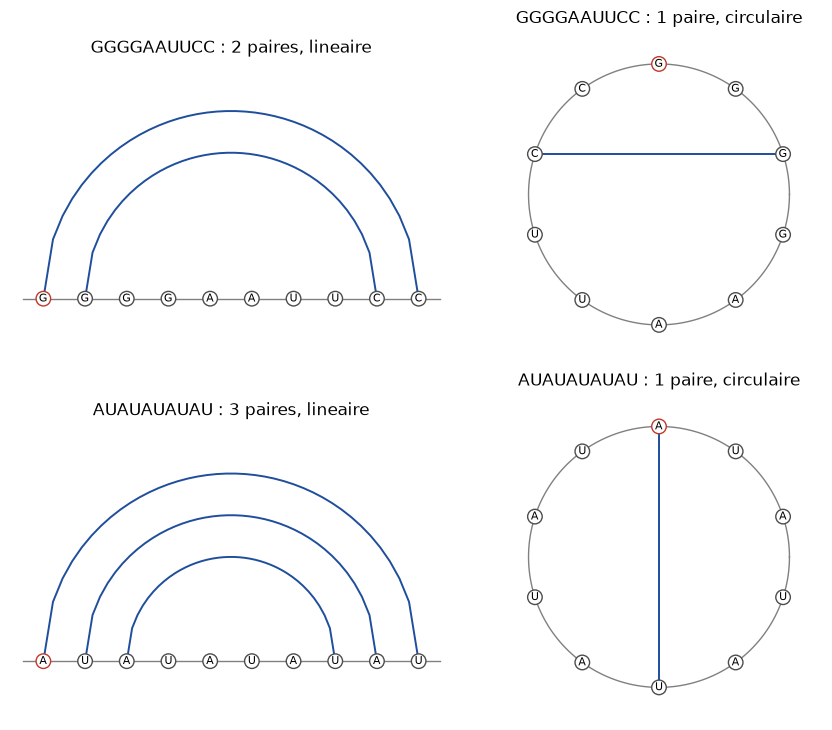

In [16]:
def trace_lineaire(ax, seq, paires, couleur='#1f4e9c'):
    # Bases sur un axe, paires en demi-cercles au-dessus
    n = len(seq)
    ax.plot([-0.5, n - 0.5], [0, 0], color='0.5', lw=1)
    for i, j in paires:
        k = np.linspace(i, j, 40)
        r = (j - i) / 2
        ax.plot(k, np.sqrt(np.maximum(r ** 2 - (k - (i + j) / 2) ** 2, 0)), color=couleur, lw=1.4)
    ax.scatter(range(n), [0] * n, s=110, color='white', edgecolor=['#c0392b'] + ['0.3'] * (n - 1), zorder=3)
    for i, lettre in enumerate(seq):
        ax.text(i, 0, lettre, ha='center', va='center', fontsize=8)
    ax.set_xlim(-0.8, n - 0.2)
    ax.set_ylim(-0.7, n / 2 + 0.7)
    ax.set_aspect('equal')
    ax.axis('off')


def trace_circulaire(ax, seq, paires, couleur='#1f4e9c'):
    # Bases sur un cercle, paires en cordes
    n = len(seq)
    angles = np.pi / 2 - 2 * np.pi * np.arange(n) / n
    x, y = np.cos(angles), np.sin(angles)
    tour = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(tour), np.sin(tour), color='0.5', lw=1)
    for i, j in paires:
        ax.plot([x[i], x[j]], [y[i], y[j]], color=couleur, lw=1.4)
    ax.scatter(x, y, s=110, color='white', edgecolor=['#c0392b'] + ['0.3'] * (n - 1), zorder=3)
    for i, lettre in enumerate(seq):
        ax.text(x[i], y[i], lettre, ha='center', va='center', fontsize=8)
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(2, 2, figsize=(9, 7.4))
for ligne, s in enumerate(('GGGGAAUUCC', 'AUAUAUAUAU')):
    for colonne, circulaire in enumerate((False, True)):
        ax = axes[ligne, colonne]
        paires = retrace(s, circulaire=circulaire)
        (trace_circulaire if circulaire else trace_lineaire)(ax, s, paires)
        compte = f'{len(paires)} paire' + ('s' if len(paires) > 1 else '')
        ax.set_title(f'{s} : {compte}, ' + ('circulaire' if circulaire else 'lineaire'))
plt.tight_layout()
plt.show()

### Lecture du résultat

**Ligne du haut, `GGGGAAUUCC`.** Sur l'axe, deux arcs : les deux paires G–C des extrémités. Sur le cercle, ces deux paires disparaissent, et pas par hasard : la première relie deux positions devenues voisines une fois le cercle fermé, la seconde deux positions séparées de trois pas seulement — toutes deux refusées par la boucle minimale. Il ne reste qu'une corde, prise au milieu de la molécule, entre les trois que la géométrie circulaire autorise.

**Ligne du bas, `AUAUAUAUAU`.** Sur l'axe, trois arcs emboîtés A–U, dont un qui embrasse presque toute la chaîne. Sur le cercle, une seule corde, un diamètre. Deux des trois paires de l'optimum linéaire sont devenues voisines à la fermeture ; la troisième est bien un diamètre, donc autorisée, mais un diamètre en croise un autre et ne peut cohabiter avec aucun : la structure circulaire se réduit à une paire, choisie parmi les cinq que la molécule admet.

Ce que la figure rend visible, c'est le sens du théorème du paragraphe 3 : la structure optimale n'est pas transportée d'une géométrie à l'autre, et l'écart n'est pas une petite retouche. C'est la contrainte de boucle, appliquée aux positions de bord devenues voisines, qui décide — et c'est pourquoi le nombre de paires perdues ne se lit pas sur la structure linéaire, mais se calcule.


## Exercices

Trois exercices, du plus direct au plus ouvert. Chacun se juge sur une mesure, pas sur une impression : la cellule d'énoncé dit ce que l'on attend, la cellule de code contient une fonction à compléter et un pilote qui l'appelle. Tant que la fonction renvoie `None`, le pilote affiche une ligne « Exercice a completer » et le carnet continue de s'exécuter de bout en bout ; une fois la fonction écrite, la même cellule imprime le tableau de mesure.

Les trois appellent les outils déjà écrits : `table_rapide` pour l'optimum, `sequence_aleatoire` pour tirer une molécule, `rotations` pour faire tourner une séquence. Aucun n'exige d'écrire un nouveau noyau de programmation dynamique.


### Exercice 1 — ce que la paire G–U apporte

Le modèle n'autorise que A–U et G–C. La paire G–U, dite wobble, existe dans l'ARN réel, un peu moins stable que les deux autres. La fonction `table_rapide` sait déjà l'ouvrir : son argument `boite=True` remplace la table des paires autorisées par celle qui contient aussi G–U et U–G.

Écrivez `gain_wobble(seq)` : pour une molécule **circulaire**, renvoyez le nombre de paires gagnées quand on passe de la boîte stricte à la boîte ouverte, c'est-à-dire l'optimum avec G–U moins l'optimum sans.

**Indice** — les deux appels diffèrent par un seul argument ; réécrire la récurrence serait du travail perdu.

Le pilote appelle votre fonction sur 60 molécules de longueur 200 et imprime la distribution des gains. Deux questions à garder en tête en lisant le tableau : le gain est-il toujours positif, et tombe-t-il souvent sur une seule valeur ? Si le gain est presque toujours le même petit nombre, c'est le signe d'une contrainte de géométrie, pas d'une abondance de sites G–U.


In [17]:
def gain_wobble(seq):
    # TODO etudiant : renvoyez le nombre de paires gagnees quand on ouvre la
    # paire G-U, pour une molecule circulaire (etape 1)
    return None


alea = np.random.default_rng(21)
gains = [gain_wobble(sequence_aleatoire(alea, 200)) for _ in range(60)]
if None in gains:
    print('Exercice a completer : le gain de la paire G-U n est pas mesure.')
else:
    valeurs, effectifs = np.unique(gains, return_counts=True)
    print('gain en paires : effectif, sur 60 molecules de longueur 200')
    for v, e in zip(valeurs, effectifs):
        print(f'   {int(v):2d} : {int(e):2d}')


Exercice a completer : le gain de la paire G-U n est pas mesure.


### Exercice 2 — la coupe ne compte pas

Le paragraphe 3 a établi que l'optimum circulaire d'une molécule ne change pas quand on fait tourner sa séquence : la molécule n'a pas d'extrémité, donc pas de point de départ. Cet exercice vérifie l'énoncé par énumération exhaustive, sur toutes les séquences possibles et pas sur un échantillon.

Écrivez `coupes_dependantes(n)` : pour les $2^n$ séquences de longueur `n` sur l'alphabet {A, U}, renvoyez la liste de celles dont l'optimum circulaire **change** quand on les fait tourner. La fonction `rotations(seq)` rend les `n` rotations d'une séquence.

**Indice** — le piège de cet exercice est l'argument oublié. Comparer les optimums **linéaires** des rotations donnerait une longue liste de séquences dépendantes, et ce serait une erreur de lecture, pas un résultat : c'est l'optimum circulaire qu'il faut demander à chaque rotation. La fonction `optimum` accepte l'argument `circulaire`, et le noyau vectorisé `table_rapide` aussi.

Le pilote parcourt `n` de 6 à 10 et imprime, pour chaque longueur, le nombre de séquences dépendantes. Le résultat attendu est une liste vide partout : si votre fonction en trouve, cherchez d'abord l'argument oublié avant de conclure que le théorème est faux.


In [18]:
def coupes_dependantes(n):
    # TODO etudiant : parmi toutes les sequences de longueur n sur l'alphabet
    # A, U, renvoyez celles dont l'optimum circulaire change selon la rotation
    # (etapes 1 et 2)
    return None


for n in (6, 7, 8, 9, 10):
    dependantes = coupes_dependantes(n)
    if dependantes is None:
        print(f'n = {n:2d} : Exercice a completer, les rotations ne sont pas comparees.')
    else:
        print(f'n = {n:2d} : {len(dependantes)} sequence(s) sur {2 ** n} '
              f'dont l optimum circulaire depend de la coupe')


n =  6 : Exercice a completer, les rotations ne sont pas comparees.
n =  7 : Exercice a completer, les rotations ne sont pas comparees.
n =  8 : Exercice a completer, les rotations ne sont pas comparees.
n =  9 : Exercice a completer, les rotations ne sont pas comparees.
n = 10 : Exercice a completer, les rotations ne sont pas comparees.


### Exercice 3 — ce qu'une substitution coûte

Une mutation remplace une base par une autre. La question posée ici est celle de la robustesse du repliement : combien de paires le passage d'une base à une autre fait-il perdre ou gagner ?

Écrivez `effet_substitution(alea, n, essais)` : pour `essais` molécules de longueur `n`, tirez une position au hasard, remplacez sa base par une des trois autres, et renvoyez la différence entre l'optimum circulaire d'après et celui d'avant. Le pilote imprime la distribution des variations sur 200 substitutions dans des molécules de longueur 100.

**Indice** — `alea.integers` tire la position, `alea.choice` la nouvelle base ; attention à ne pas remplacer une base par elle-même, sinon la substitution ne mesure rien. La différence est signée : négative quand le repliement perd des paires.

Deux lectures possibles de la même distribution : la variation **moyenne** dit si une mutation coûte en général quelque chose, et la **part des substitutions sans effet** dit combien de mutations sont muettes du point de vue du repliement. Les deux se lisent sur le même tableau, et la seconde est généralement la plus grande des deux surprises.


In [19]:
def effet_substitution(alea, n, essais):
    # TODO etudiant : pour essais molecules de longueur n, tirez une position
    # et remplacez sa base par une autre ; renvoyez la difference entre
    # l'optimum circulaire avant et apres (etapes 1 et 2)
    return None


alea = np.random.default_rng(42)
effets = effet_substitution(alea, 100, 200)
if effets is None:
    print('Exercice a completer : l effet d une substitution n est pas mesure.')
else:
    valeurs, effectifs = np.unique(effets, return_counts=True)
    print('variation du nombre de paires : effectif, sur 200 substitutions')
    for v, e in zip(valeurs, effectifs):
        print(f'   {int(v):2d} : {int(e):3d}')


Exercice a completer : l effet d une substitution n est pas mesure.


## En résumé

- Une molécule d'ARN circulaire n'a pas d'extrémité : sa structure secondaire est un ensemble de cordes deux à deux non croisées, et la contrainte de boucle minimale s'applique aux **deux** arcs du cercle.
- L'optimum circulaire se calcule avec la même récurrence que l'optimum linéaire, en changeant un seul test : une paire est autorisée quand ses deux distances le long du cercle dépassent la boucle minimale. Même coût cubique, même retrace.
- L'optimum circulaire ne dépend pas de la coupe, l'optimum linéaire en dépend, et l'écart entre les deux n'est pas le nombre de paires qui referment le cercle : c'est une propriété de l'optimum, pas de la structure linéaire.
- Deux contrôles indépendants — énumération exhaustive des structures d'un côté, programme en nombres entiers de l'autre — retrouvent le noyau sur des centaines de cas, sans un seul écart ; le programme exige une contrainte de degré par base, sans quoi il empile deux paires sur la même position.
- Le plafond de composition `min(nA,nU) + min(nG,nC)` borne le nombre de paires. Avec la longueur, l'écart moyen au plafond grandit alors que l'écart entre linéaire et circulaire diminue : fermer le cercle coûte peu aux longues molécules, et davantage aux courtes.
- Le nombre de paires perdues à la fermeture reste petit — au plus deux par molécule sur les tailles testées — mais il ne se lit pas sur la structure linéaire : la paire interdite peut n'y être qu'une sans que l'optimum change, ou plusieurs sans coûter une paire.
- Le critère du plus grand nombre de paires ne désigne pas **une** structure. À neuf bases, aucune des 510 séquences n'admet de repliement unique, et ce n'est pas une observation : la géométrie du cycle de neuf sommets l'impose.
- Ce que la feuille suivante ajoute n'est pas un calcul plus rapide : c'est un autre objectif, une énergie qui pèse les paires et les boucles au lieu de les compter, et départage les ex æquo.


## Statut de ce que ce carnet établit

| Statut | Contenu |
|---|---|
| **Démontré ici** | Le théorème du paragraphe 3 : équivalence avec un optimum linéaire sur les paires autorisées au sens circulaire, invariance de l'optimum circulaire par rotation, et non-identité avec le maximum des optimums linéaires pris sur les coupes. L'argument de parité à neuf bases, et le compte exact à huit bases. |
| **Mesuré, non démontré** | Les écarts nuls entre le noyau, l'énumération exhaustive et le programme en nombres entiers ; les tableaux de gains, d'écarts au plafond, d'effet de la boucle minimale, de composition et d'unicité. Ces mesures portent sur un nombre fini de séquences, tirées avec des graines fixées et reproduites par les cellules. |
| **Cité, non redémontré** | Le fait biologique que les viroïdes sont des ARN circulaires de 250 à 400 nucléotides, non codants, capables de se répliquer et de rendre malades les plantes, et qu'ils sont les plus petits réplicateurs connus — Pallas, Di Serio et Suzuki (2023), fragments exacts cités au paragraphe 1. |
| **Ouvert** | Le passage du compte de paires à une énergie réelle, avec des paramètres mesurés sur des molécules ; la structure effective des viroïdes, qui n'est pas lue dans ce carnet ; le rôle de la topologie au-delà du seul caractère circulaire (superenroulement, circularisation covalente). |


## Limites

**Le modèle ne connaît pas l'énergie.** Toutes les paires autorisées valent une. Une paire G–C et une paire A–U comptent pareil, et une boucle de trois positions pèse autant qu'une boucle de trente. C'est ce qui rend l'optimum calculable par une récurrence de comptage, et c'est aussi ce qui le rend indifférent à la thermodynamique : les structures départagées ici le sont par des contraintes de forme, jamais par des énergies d'empilement.

**La géométrie est réduite à une contrainte.** Une structure est un ensemble de cordes non croisées ; on ne modélise ni l'épaisseur de l'hélice, ni les angles des boucles, ni les pseudonœuds, qui croisent précisément ce que le modèle interdit. Une molécule réelle peut adopter des appariements que ce carnet déclare impossibles.

**Un ARN circulaire réel n'est pas un cercle abstrait.** Le caractère circulaire est ici une propriété de la séquence, pas de la molécule : on ne représente ni le superenroulement, ni la circularisation covalente, ni les protéines qui se lient et contraignent la forme. Le cercle du carnet est une topologie, pas un objet chimique.

**Les contrôles croisés portent sur des échantillons.** L'énumération exhaustive couvre toutes les séquences sur l'alphabet {A, U} jusqu'à douze bases ; au-delà, et sur l'alphabet complet, les comparaisons portent sur des séquences tirées. Un écart nul sur ces tirages rend une erreur de noyau très improbable, il ne prouve pas l'absence d'erreur partout.

**Aucune séquence de viroïde n'est lue.** Le paragraphe 1 cite la présentation des viroïdes par leurs auteurs ; il n'ouvre aucun génome, ne replie aucune molécule réelle et ne compare aucun résultat à une structure publiée. Le lien entre le modèle et la biologie des viroïdes reste programmatique : c'est ce que la série annonce, pas ce qu'elle a mesuré.


## Références

**Source citée au paragraphe 1**

Pallas, V., Di Serio, F., Suzuki, N. (2023). *The simplest RNA replicons, viroids: A tribute to Ricardo Flores*. Virus Research, 323, 198996. DOI : 10.1016/j.virusres.2022.198996. Article en accès libre (CC BY-NC-ND), PMC10194228.

Copie archivée du texte intégral : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\2023 - Pallas Di Serio Suzuki - The simplest RNA replicons, viroids - A tribute to Ricardo Flores (Virus Research 323, 198996, PMC10194228, CC BY-NC-ND, OA).xml`

Passages utilisés : la définition des viroïdes comme ARN circulaires non codants de 250 à 400 nucléotides, capables de se répliquer et de rendre malades les plantes ; la mention qu'ils sont les plus petits réplicateurs connus ; la classification en deux familles selon le site et la stratégie de réplication et selon la structure secondaire.

**Méthodes classiques, citées de seconde main**

Nussinov, R., Jacobson, A. B. (1980). Fast algorithm for predicting the secondary structure of single-stranded RNA. *Proceedings of the National Academy of Sciences*, 77(11), 6309-6313.

Cette publication n'est **pas** archivée dans le gisement bibliographique de la flotte à la date de rédaction : elle est citée pour situer la récurrence de comptage, pas pour attribuer un résultat mesuré ici. Le carnet ne la cite nulle part comme source d'une valeur.

**Dans la série**

La feuille précédente établit le repliement linéaire, l'énergie d'un réseau et l'inégalité isopérimétrique : [Structures-02](Structures-02-Repliement-Reseau-Energie-Isoperimetrie-Python.ipynb). La suivante, annoncée mais non encore écrite, remplace le compte de paires par une énergie ; elle sera liée ici quand elle existera, plutôt que d'annoncer un chemin qui ne mène nulle part.


## Pour aller plus loin

- **Rendre toutes les structures optimales, pas une.** La fonction `structures` énumère ; au-delà de douze bases, il faut une récurrence qui mémorise les ensembles de structures, et la question du coût se pose alors sérieusement.
- **Peser au lieu de compter.** Ajouter une énergie par paire et par type de boucle, puis comparer les structures obtenues aux optimums de comptage : c'est la feuille suivante, et c'est là que le modèle devient falsifiable contre des mesures.
- **Sortir du tirage uniforme.** L'unicité a été mesurée sur des séquences tirées au hasard ; sur des génomes réels, la composition n'est pas uniforme, et la question « combien de structures optimales » change de réponse.
- **Passer du cercle à des topologies plus riches.** Pseudonœuds et appariements croisés localement autorisés sont hors du modèle ; les traiter demande d'abandonner la programmation dynamique sur intervalles, pas de la compliquer.

Le pli étudié ici — une contrainte de forme qui se traduit en une contrainte d'indices — se retrouve dans d'autres séries du dépôt : les mêmes récurrences d'intervalle servent en [Search](../../Search/README.md) pour les chaînes de Markov cachées, en [Probas](../../Probas/README.md) pour la programmation dynamique sur arbres, et les réseaux de la feuille précédente sont repris en [Dynamiques](../Dynamiques/README.md).

[↑ Retour au sommaire de la série](../README.md)
